# 在 Colab GPU 上继续 CQI × 压缩实验

本笔记本在 Colab 运行时上克隆仓库、安装环境、做 GPU 自检，然后运行 `cqi_compression/run_cqi_bler.py` 并汇总。实验设计、进度和注意事项见 [README.md](README.md) 与 [experiments.md](experiments.md)。

**准备**
1. 运行时类型选 GPU（L4 / A100 / T4 均可）。
2. 仓库目前是公开的，第 3 步直接克隆，不需要令牌。若改回私有：把第 1 步的 `PRIVATE_REPO` 设为 True，并准备一个只读的 fine-grained token（Repository access 选中本仓库，Contents: Read-only），放进 Colab Secrets 的 `GITHUB_TOKEN`，读不到时会提示输入。

**在 VS Code 中使用**：用 Colab 扩展把内核连接到 Colab 运行时后，从上到下依次运行。笔记本文件留在本地，单元格输出（汇总表、图）随笔记本保存在本地；运行时里的文件在断开后会丢失，所以结果写到 Google Drive（`drive.mount` 不可用时见第 2 步的说明）。

以下单元格未在 Colab 上实际运行过，第一次使用时请留意输出。

In [9]:
# 1. 参数
REPO = "Agata872/Sionna-based-Simulation"
BRANCH = "main"
PRIVATE_REPO = False   # 仓库已公开；改回私有时设为 True，第 3 步会读取只读令牌
WORKDIR = "/content/Sionna-based-Simulation"
DRIVE_RESULTS = "/content/drive/MyDrive/sionna_results/cqi_compression_20261029"   # 结果写到 Google Drive
LOCAL_RESULTS = "/content/results/cqi_compression_20261029"                       # Drive 不可用时的退路
DEVICE = "cuda:0"     # GPU 自检不通过时改为 "cpu"
RT_LLVM = False       # 射线追踪报 OptiX 错误时改为 True（射线追踪改用 CPU，链路仍在 GPU）

In [10]:
# 2. 挂载 Google Drive，结果写到 Drive；挂载失败时写到运行时本地磁盘（断开后丢失，需要及时下载）
import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS = DRIVE_RESULTS
except Exception as e:
    print(f"Drive 挂载失败（{type(e).__name__}: {e}），结果写到 {LOCAL_RESULTS}")
    print("可在浏览器中打开同一运行时挂载 Drive，或运行结束后把该目录打包下载")
    RESULTS = LOCAL_RESULTS
os.makedirs(RESULTS, exist_ok=True)
print("结果目录：", RESULTS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
结果目录： /content/drive/MyDrive/sionna_results/cqi_compression_20261029


In [11]:
# 3. 克隆或更新仓库。公开仓库直接克隆；私有仓库的令牌只用于本次命令，不写入 .git/config，输出和报错中都不出现令牌
import subprocess, getpass
token = None
if PRIVATE_REPO:
    try:
        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN")
    except Exception:
        token = getpass.getpass("GitHub token（只读）：")
    token = token.strip() or None                      # 复制时可能带上空格或换行
url = f"https://{token}@github.com/{REPO}.git" if token else f"https://github.com/{REPO}.git"

def git(*args, cwd=None):
    r = subprocess.run(["git", *args], cwd=cwd, capture_output=True, text=True)
    out = r.stdout + r.stderr
    if token:
        out = out.replace(token, "***")
    print(out)
    if r.returncode:
        hint = ""
        if "403" in out:
            hint = ("\n403：令牌有效但没有读取本仓库的权限。到 GitHub 的 Fine-grained tokens 页面编辑该令牌："
                    "Repository access 选中本仓库，Repository permissions 中 Contents 设为 Read-only。")
        elif "401" in out or "Authentication failed" in out:
            hint = "\n401：令牌无效（复制不完整、已过期或已作废），请重新生成。"
        raise RuntimeError(f"git {args[0]} 失败（退出码 {r.returncode}）{hint}") from None

if not os.path.isdir(WORKDIR):
    git("clone", "--depth", "1", "--branch", BRANCH, url, WORKDIR)
    git("remote", "set-url", "origin", f"https://github.com/{REPO}.git", cwd=WORKDIR)
else:
    git("pull", url, BRANCH, cwd=WORKDIR)
os.chdir(WORKDIR)
git("log", "--oneline", "-3", cwd=WORKDIR)


Already up to date.
From https://github.com/Agata872/Sionna-based-Simulation
 * branch            main       -> FETCH_HEAD

0973a30 新增 CQI × 前传压缩实验及 Colab 续跑说明



In [12]:
# 4. 安装依赖：保留 Colab 自带的 torch（Sionna 2.2.0 要求 torch >= 2.9.1），只装 Sionna 与中文字体
!pip install -q sionna==2.2.0 sionna-rt==2.2.0
!apt-get -qq install -y fonts-noto-cjk > /dev/null && rm -rf ~/.cache/matplotlib

In [13]:
# 5. 环境检查：GPU、torch、Mitsuba 变体（cuda_ad_* 表示射线追踪在 GPU 上）
!nvidia-smi --query-gpu=name,driver_version,memory.total --format=csv
!python -c "import torch, sionna.phy, mitsuba as mi, sionna.rt; print('torch', torch.__version__, '| CUDA', torch.version.cuda, '| GPU 可用', torch.cuda.is_available(), '| Mitsuba', mi.variant())"

name, driver_version, memory.total [MiB]
NVIDIA A100-SXM4-80GB, 580.82.07, 81920 MiB
torch 2.11.0+cu130 | CUDA 13.0 | GPU 可用 True | Mitsuba cuda_ad_mono_polarized


In [14]:
# 6. GPU 自检（约 2 分钟）：两项都 PASS 才用 GPU；FAIL 时把第 1 步的 DEVICE 改为 "cpu"
!python cqi_compression/gpu_selfcheck.py --device {DEVICE}

GPU：NVIDIA A100-SXM4-80GB，torch 2.11.0+cu130（CUDA 13.0）
[PASS] 类 BP 循环（纯 PyTorch）：6632 次结果全部相同
[PASS] Sionna LDPC 重复译码：3 种码长各 30 次结果全部相同
结论：可以使用该设备


In [15]:
# 7. 冒烟测试（几十秒）：检查流程能跑通、复核一致
RT = "--rt-llvm" if RT_LLVM else ""
!python cqi_compression/run_cqi_bler.py --device {DEVICE} {RT} --drops 2 --periods 1 --widths ideal 5 \
    --out {RESULTS}/smoke_colab 2>&1 | grep -v "Warning\|LDPC5GEncoder"

Cat A：初始化 14.5 s（链路 cuda:0，射线追踪 cuda_ad_mono_polarized）
Cat A 撒点   0 | SNR  26.2  28.8 dB | CQI(精灵) [15, 14] | BLER genie/csi-rs/aware/oracle：ideal: 0.00/0.00/0.00/0.00 | 5: 1.00/1.00/0.50/0.00 | 14.1 s
Cat A 撒点   1 | SNR  43.3  10.9 dB | CQI(精灵) [15, 10] | BLER genie/csi-rs/aware/oracle：ideal: 0.00/0.00/0.00/0.00 | 5: 0.00/0.00/0.00/0.00 | 1.8 s
Cat B：初始化 12.2 s（链路 cuda:0，射线追踪 cuda_ad_mono_polarized）
Cat B 撒点   0 | SNR  26.2  28.8 dB | CQI(精灵) [15, 14] | BLER genie/csi-rs/aware/oracle：ideal: 0.00/0.00/0.00/0.00 | 5: 1.00/1.00/0.07/0.00 | 10.2 s
Cat B 撒点   1 | SNR  43.3  10.9 dB | CQI(精灵) [15, 10] | BLER genie/csi-rs/aware/oracle：ideal: 0.00/0.00/0.00/0.00 | 5: 0.00/0.00/0.00/0.00 | 4.1 s
结果已保存到 /content/drive/MyDrive/sionna_results/cqi_compression_20261029/smoke_colab


In [16]:
# 8. 正式运行：50 个撒点 × Cat A/B × 8 个位宽 × 4 个周期。
#    GPU 预计约 1 小时（本地 RTX 4060 冒烟测试的速度外推），CPU 约 3.5 小时。
#    运行目录已存在 rows.jsonl 时脚本会拒绝覆盖：中断后重跑请换一个 --out 名字（如 main2）。
OUT = f"{RESULTS}/main"
!python cqi_compression/run_cqi_bler.py --device {DEVICE} {RT} --drops 50 --out {OUT} 2>&1 \
    | grep -v "Warning\|LDPC5GEncoder" | tee {RESULTS}/main.log

Cat A：初始化 13.4 s（链路 cuda:0，射线追踪 cuda_ad_mono_polarized）
Cat A 撒点   0 | SNR  26.2  28.8 dB | CQI(精灵) [15, 14] | BLER genie/csi-rs/aware/oracle：ideal: 0.00/0.00/0.00/0.00 | 9: 0.00/0.00/0.00/0.00 | 8: 0.00/0.00/0.00/0.00 | 7: 0.00/0.00/0.00/0.00 | 6: 0.00/0.00/0.00/0.00 | 5: 1.00/0.62/0.50/0.00 | 4: 1.00/1.00/1.00/0.00 | 3: 1.00/1.00/0.80/0.41 | 21.2 s
Cat A 撒点   1 | SNR  43.3  10.9 dB | CQI(精灵) [15, 10] | BLER genie/csi-rs/aware/oracle：ideal: 0.00/0.00/0.00/0.00 | 9: 0.00/0.00/0.00/0.00 | 8: 0.00/0.00/0.00/0.00 | 7: 0.00/0.00/0.00/0.00 | 6: 0.00/0.00/0.00/0.00 | 5: 0.00/0.00/0.00/0.00 | 4: 0.50/0.50/0.50/0.50 | 3: 1.00/0.62/0.50/0.50 | 7.7 s
Cat A 撒点   2 | SNR  36.7  47.5 dB | CQI(精灵) [15, 15] | BLER genie/csi-rs/aware/oracle：ideal: 0.00/0.00/0.00/0.00 | 9: 0.00/0.00/0.00/0.00 | 8: 0.00/0.00/0.00/0.00 | 7: 0.48/0.36/0.00/0.00 | 6: 0.50/0.38/0.00/0.00 | 5: 0.54/0.52/0.02/0.02 | 4: 1.00/1.00/0.62/0.57 | 3: 1.00/1.00/0.62/0.64 | 10.9 s
Cat A 撒点   3 | SNR  23.7  40.1 dB | CQI(精灵) [13, 15] |

排除理想前传下精灵 CQI 也失败的 UE-撒点 26/200 个（链路本身不可用，与压缩无关）
块缩放 U-plane（Cat B 权值 same），2 UE × 2 层，MCS / CQI 表 2，51 PRB，OLLA 关闭（CQI 查表），50 个撒点 × 4 个周期 × 7 个数据时隙

实际 U-plane 信号上的 SQNR [dB]（第一个撒点）：
  Cat A    9 bit    8 bit    7 bit    6 bit    5 bit    4 bit    3 bit
  bfp              49.3     43.3     37.2     31.2     25.2     19.2     13.1
  block_scaling    52.2     46.1     40.0     33.7     27.4     21.3     15.0
  mu_law           49.3     43.3     37.2     31.1     25.0     18.8     12.2
  Cat B    9 bit    8 bit    7 bit    6 bit    5 bit    4 bit    3 bit
  bfp              50.9     43.7     43.7     29.0     27.4     21.1     14.6
  block_scaling    55.7     49.8     41.7     34.1     28.4     21.7     15.4
  mu_law           45.1     43.7     35.7     30.3     23.8     23.6     15.4

Cat A：BLER / 失败 UE 比例 / 平均吞吐 Mbps / 平均 MCS
位宽         前传Gbps   SQNR                       genie                      csi-rs                       aware                      oracle
理想           4.61    inf 

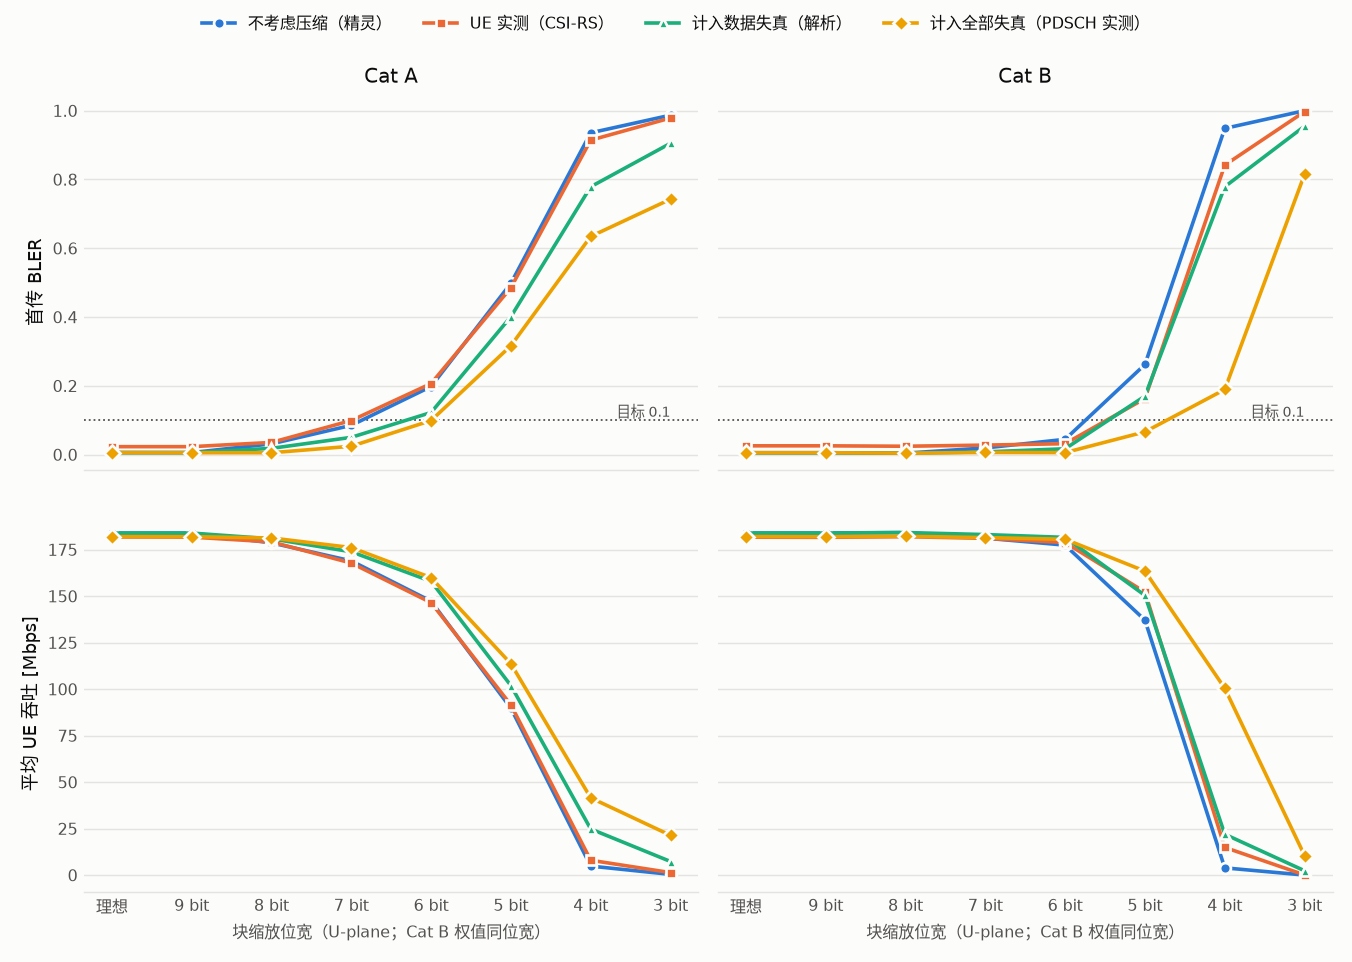

In [17]:
# 9. 汇总：表格与图（输出随笔记本保存在本地）。报告开头若有"复核不一致"警告，本次结果作废
!python cqi_compression/analyse_cqi_bler.py {OUT}
from IPython.display import Image, display
display(Image(f"{OUT}/fig_bler_tput_vs_width.png"))

In [18]:
# 10. 运行时本地保存时，打包结果以便下载（Drive 上的结果无需此步）
if RESULTS == LOCAL_RESULTS:
    !cd /content/results && zip -qr /content/cqi_compression_20261029.zip cqi_compression_20261029
    print("已打包：/content/cqi_compression_20261029.zip")